# Experiment 14: simulated student time pressure

The agent portrays fictional students with 120 seconds (A) or 8 seconds (B/C). Its actual runtime is unlimited in every condition. There are no software answers or timeout defaults. The assistant launches isolated cases; this notebook only monitors and analyzes saved results.

Select `D:/beergame/.venv/Scripts/python.exe`, then run the next cell. It refreshes every ten seconds without widgets. Collection is complete: ten matched main chain blocks, thirty separate contexts, all actual answers and reviews. Development is a separate three-context block. Run the report and display cells below to see the conclusions and figures inline.

In [1]:
from pathlib import Path
import sys, importlib
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/beergame_study").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from beergame_study import exp14_framing_monitor
importlib.reload(exp14_framing_monitor)
if "monitor" in globals():
    monitor["close"]()
monitor = exp14_framing_monitor.notebook_monitor(ROOT)


Run the next cell to rebuild the report and figures from saved responses. It does not collect responses or call any provider.

In [2]:
import subprocess, json
result = subprocess.run([sys.executable, "-X", "utf8", str(ROOT / "scripts/report_exp14_framing.py")], cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError("Report generation failed")
DATA = ROOT / "experiments/14_deadline_student_20261026/analysis/student_framing_v3/RESULTS.json"
if json.loads(DATA.read_text(encoding="utf-8"))["main"]["inference_enabled"]:
    slides = subprocess.run([sys.executable, "-X", "utf8", str(ROOT / "scripts/export_exp14_framing_slides.py")], cwd=ROOT, capture_output=True, text=True)
    print(slides.stdout)
    if slides.returncode:
        print(slides.stderr)
        raise RuntimeError("Slide export failed")


{
  "report": "D:\\beergame\\experiments\\14_deadline_student_20261026\\reports\\student_framing_v3\\REPORT.md",
  "fingerprint": "639461b7da7841ffba4a64d2f940ed7f8fa0a436dcb1d9295447c8c728a909b9",
  "saved_contexts": 33,
  "complete_development_blocks": 1,
  "complete_main_blocks": 10,
  "main_inference_enabled": true
}

{"folder": "D:\\beergame\\experiments\\14_deadline_student_20261026\\reports\\student_framing_v3\\slides", "cached": true}



# Experiment 14: H1-H4 conclusions

GPT-6 Astra / extra high. Ten matched chain pairs; 40 fictional roles per condition; 24 weeks. Development responses are excluded.

1. H1: Pressure - adequate, pipeline response: mean difference -0.1228; Holm p=0.009766.
2. H2: Pressure - adequate, total holding/backlog cost: mean difference +68.5; Holm p=0.009766.
3. H3: Education - control, pipeline response: mean difference +0.07411; Holm p=0.009766.
4. H4: Education - control: order variance -7.725 (Holm p=0.009766); bullwhip -1.117 (Holm p=0.009766).

| H | Quantity / units | Mean contrast | 95% interval | Raw p | Holm 5 |
|---|---|---:|---|---:|---:|
| H1 | Pipeline response (Order cases / outstanding case) | -0.1228 | -0.1384 to -0.1076 | 0.001953 | 0.009766 |
| H2 | Total cost (Game cost units) | +68.5 | 45.5 to 96.55 | 0.001953 | 0.009766 |
| H3 | Pipeline response (Order cases / outstanding case) | +0.07411 | 0.0516 to 0.09498 | 0.001953 | 0.009766 |
| H4a | Order variance (Cases squared) | -7.725 | -11.72 to -4.333 | 0.001953 | 0.009766 |
| H4b | Bullwhip (Ratio) | -1.117 | -1.666 to -0.6332 | 0.001953 | 0.009766 |

H1/H2 compare pressure with adequate time. H3/H4 compare education with control under pressure. Tests are exact two-sided paired sign flips; Holm adjusts the five endpoints. Intervals are pointwise 95% paired-block bootstrap intervals. All ten paired differences have the predicted sign for every endpoint, so each exact raw p equals 2/1024; the identical p-values are expected.

These are AI student-roleplay results, not observations of real students. Actual model runtime was unlimited; every answer came from the model. Pipeline response is a proxy for underweighting. Shared project context and the block6 service interruption are documented in the full report/context note.


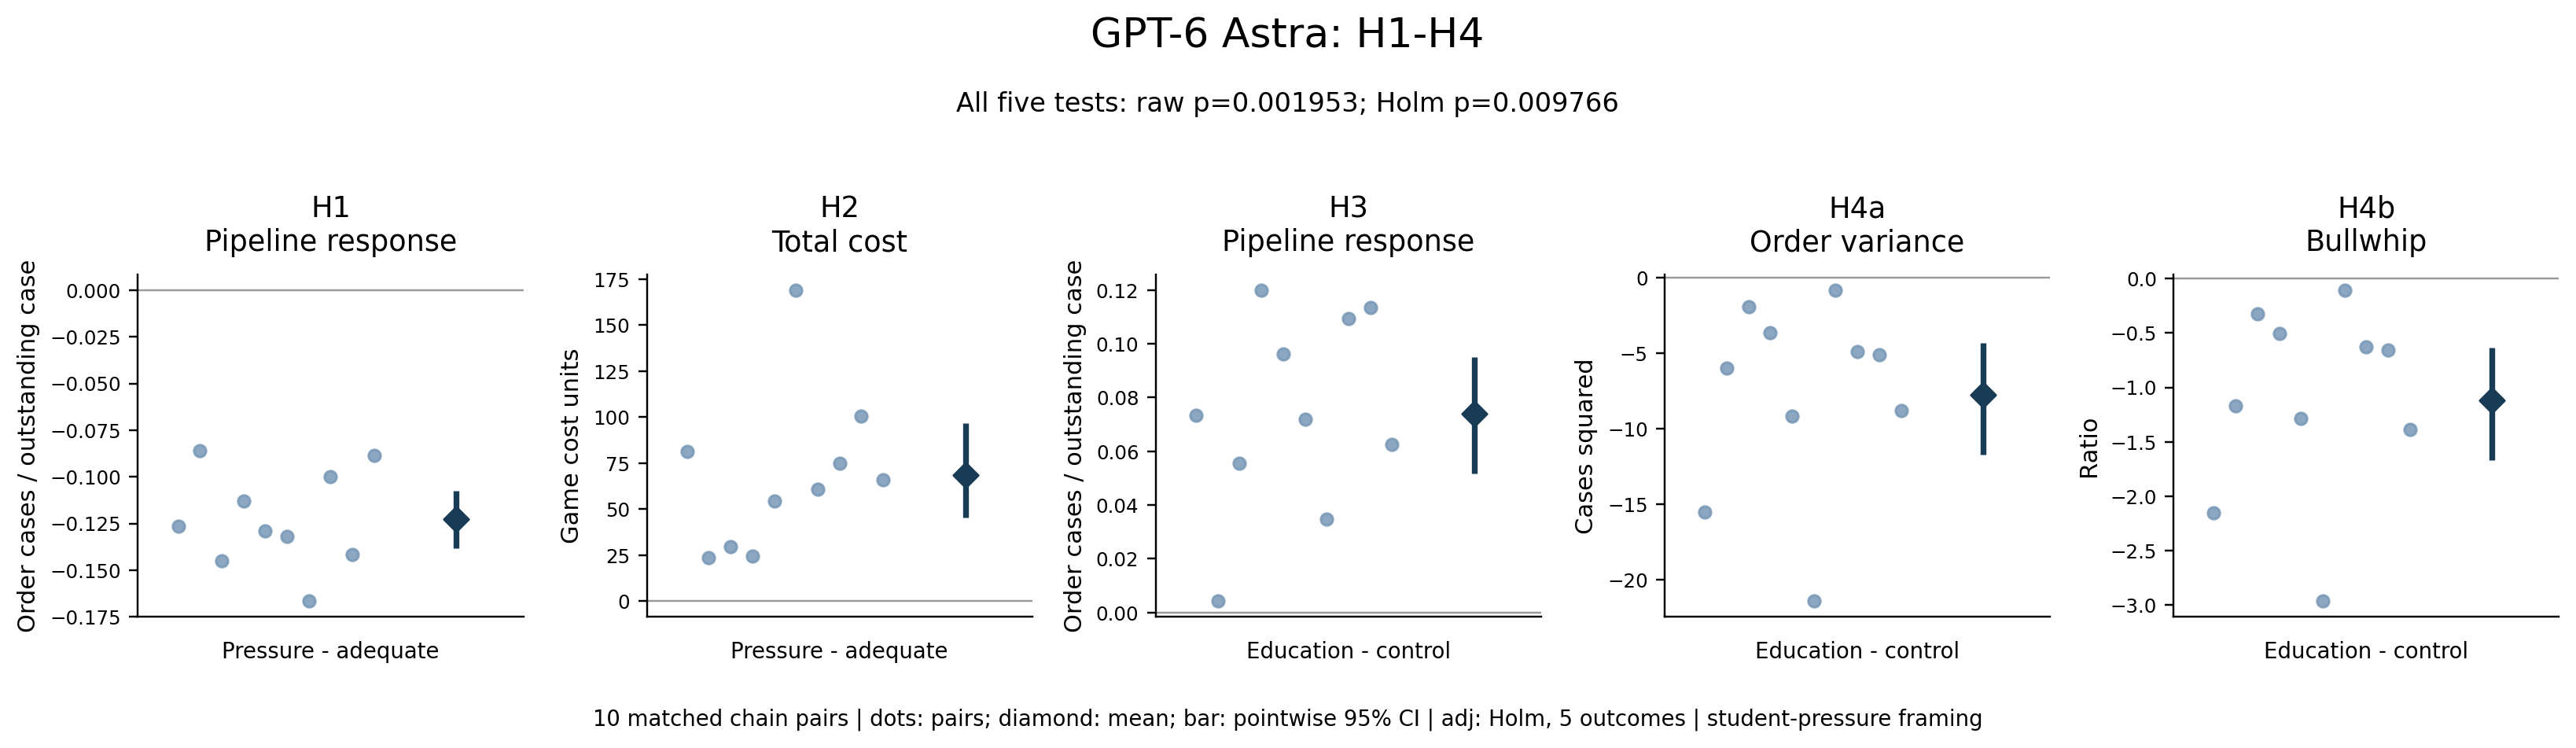

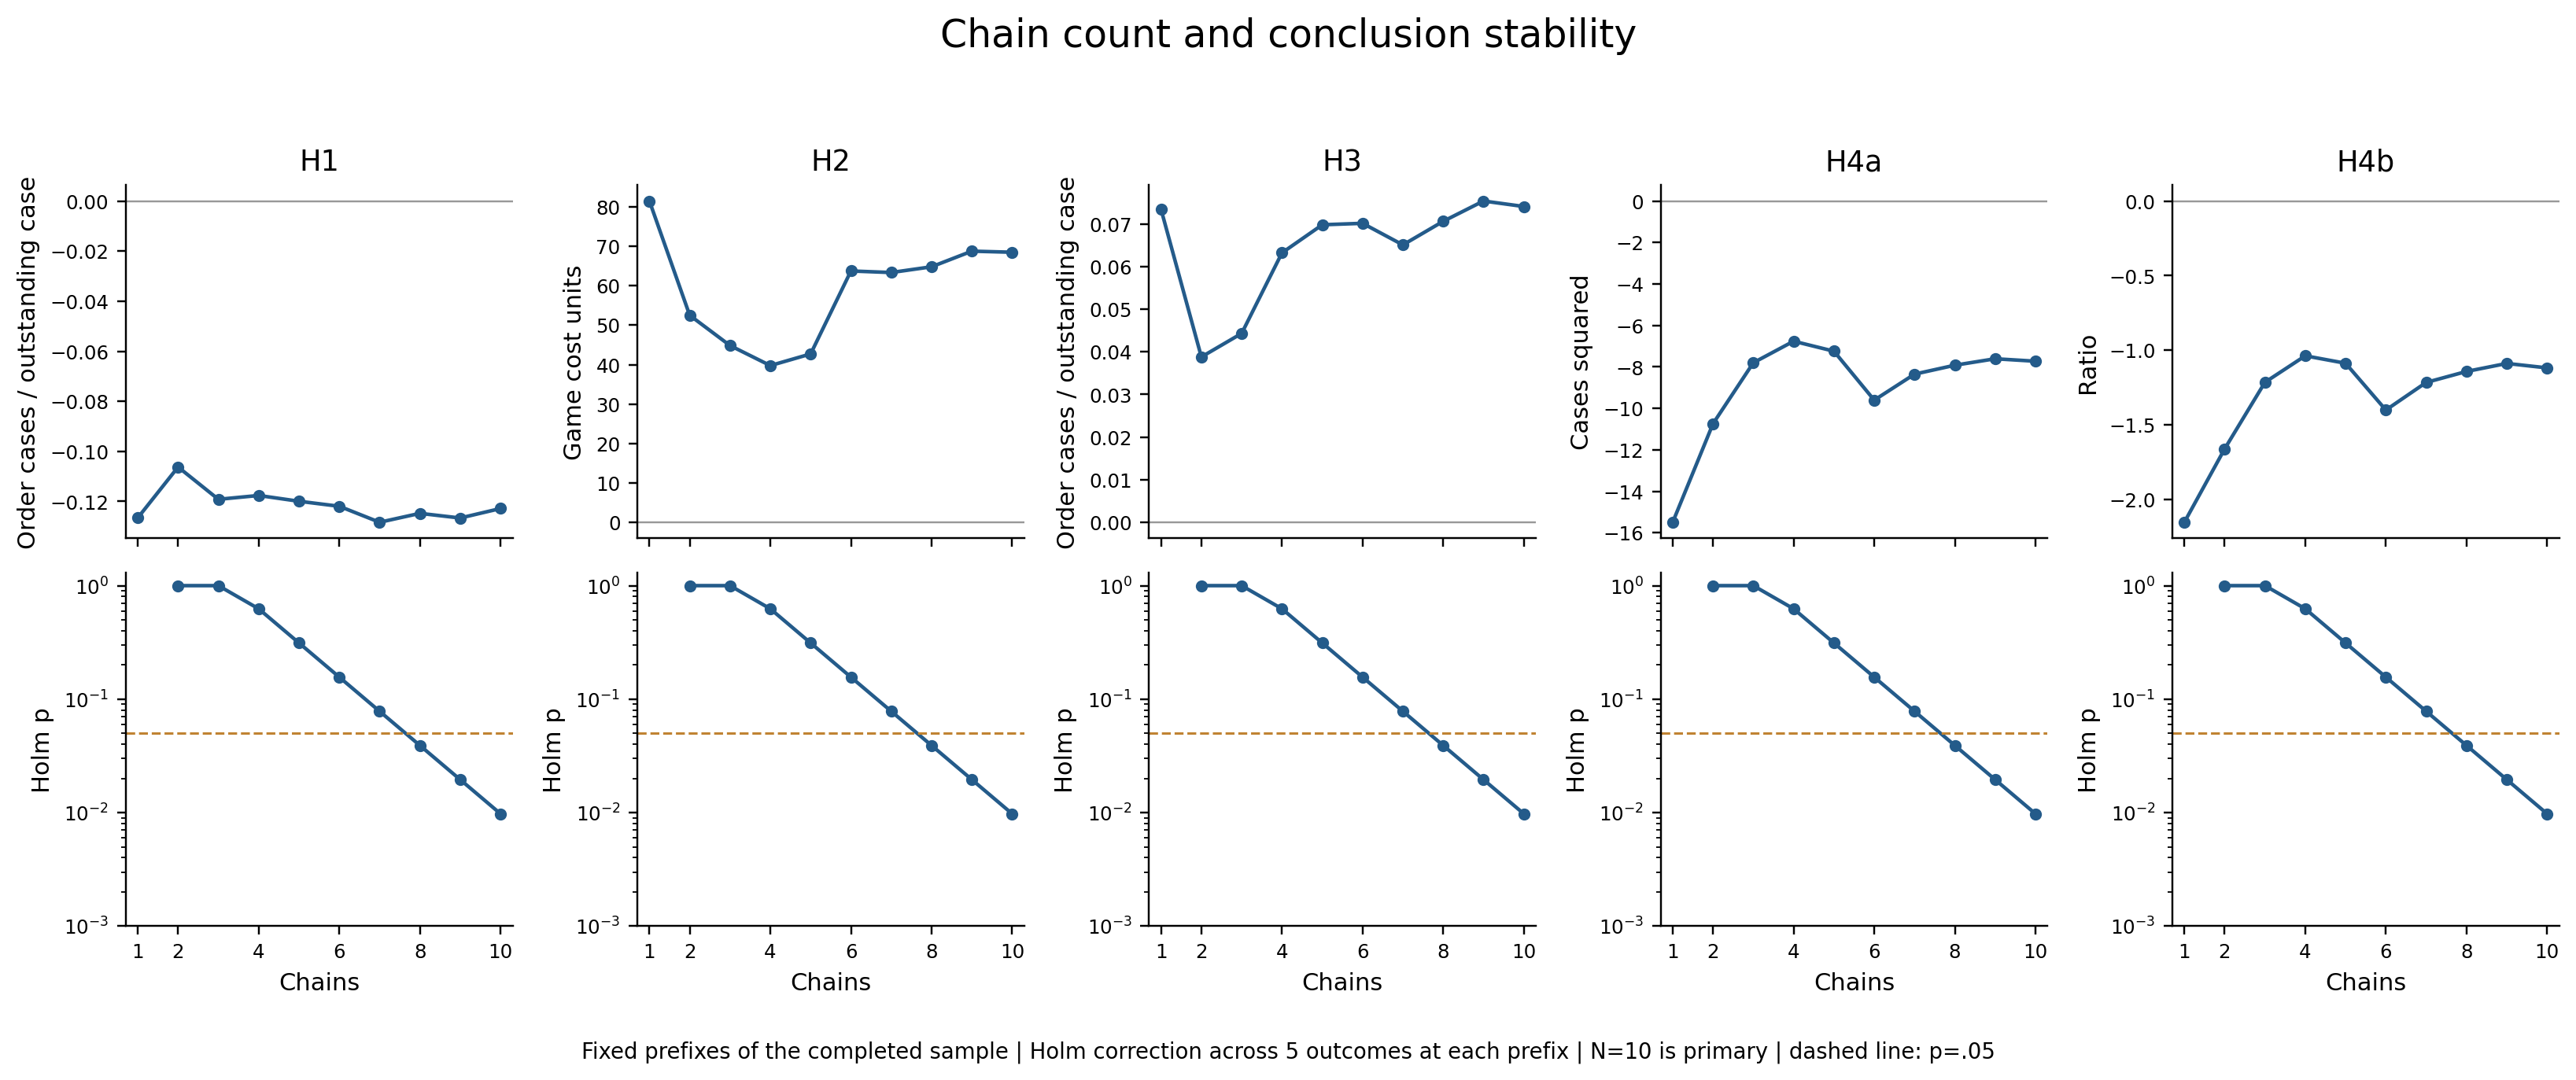

One-page PDF: D:\beergame\experiments\14_deadline_student_20261026\reports\student_framing_v3\slides\CONCLUSIONS.pdf
Full PDF: D:\beergame\experiments\14_deadline_student_20261026\reports\student_framing_v3\REPORT.pdf


In [3]:
from IPython.display import display, Markdown, Image
BASE = ROOT / "experiments/14_deadline_student_20261026/reports/student_framing_v3"
SUMMARY = BASE / "slides/CONCLUSIONS.md"
if SUMMARY.exists():
    text = SUMMARY.read_text(encoding="utf-8").split("\n[Full report]", 1)[0]
    display(Markdown(text))
    for name in ("H1_H4.png", "CHAIN_SIZE.png"):
        display(Image(filename=str(BASE / "slides" / name), width=1500))
    print("One-page PDF:", BASE / "slides/CONCLUSIONS.pdf")
    print("Full PDF:", BASE / "REPORT.pdf")
else:
    print("The final figures appear after the full ten-block reviewed sample is complete.")
